<a href="https://colab.research.google.com/github/piriyadharshiniN/24ADI006-DL-Lab/blob/main/DL_Exp_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Name: Piriyadharshini N
Roll no.: 24BAD086
Experiment: 8

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)


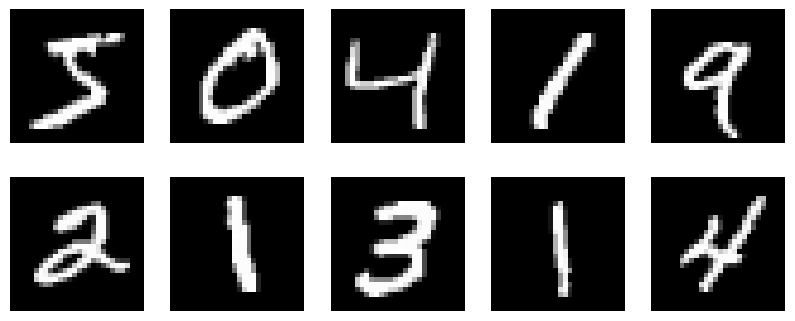

Training data after flattening: (60000, 784)
Testing data after flattening: (10000, 784)


In [1]:
print("Name: Piriyadharshini N\nRoll no.: 24BAD086\nExperiment: 8\n")

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist

# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Display dataset information
print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

# Display sample images
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.axis('off')

plt.show()

# Normalize pixel values
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Flatten images into 784-dimensional vectors
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

# Display final dimensions
print("Training data after flattening:", x_train.shape)
print("Testing data after flattening:", x_test.shape)

In [2]:
print("Name: Piriyadharshini N\nRoll no.: 24BAD086\nExperiment: 8\n")

from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model

# Define input layer
input_layer = Input(shape=(784,))

# Encoder
encoded = Dense(128, activation='relu')(input_layer)
encoded = Dense(64, activation='relu')(encoded)
latent = Dense(32, activation='relu')(encoded)

# Decoder
decoded = Dense(64, activation='relu')(latent)
decoded = Dense(128, activation='relu')(decoded)
output_layer = Dense(784, activation='sigmoid')(decoded)

# Create Autoencoder model
autoencoder = Model(input_layer, output_layer)

# Create Encoder model
encoder = Model(input_layer, latent)

# Create Decoder model
decoder_input = Input(shape=(32,))
decoder_output = autoencoder.layers[-3](decoder_input)
decoder_output = autoencoder.layers[-2](decoder_output)
decoder_output = autoencoder.layers[-1](decoder_output)

decoder = Model(decoder_input, decoder_output)

# Display model summaries
print("ENCODER SUMMARY")
encoder.summary()

print("DECODER SUMMARY")
decoder.summary()

print("AUTOENCODER SUMMARY")
autoencoder.summary()

Name: Piriyadharshini N
Roll no.: 24BAD086
Experiment: 8

ENCODER SUMMARY


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,816 (432.88 KB)

 Trainable params: 110,816 (432.88 KB)

 Non-trainable params: 0 (0.00 B)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

Name: Piriyadharshini N
Roll no.: 24BAD086
Experiment: 8

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - loss: 0.2432 - val_loss: 0.1660
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - loss: 0.1526 - val_loss: 0.1391
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.1336 - val_loss: 0.1260
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.1232 - val_loss: 0.1178
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.1169 - val_loss: 0.1134
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.1124 - val_loss: 0.1089
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.1089 - val_loss: 0.1061
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.1064 - val_loss: 0.1036
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.1041 - val_loss: 0.1016
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.1020 - val_loss: 0.0998


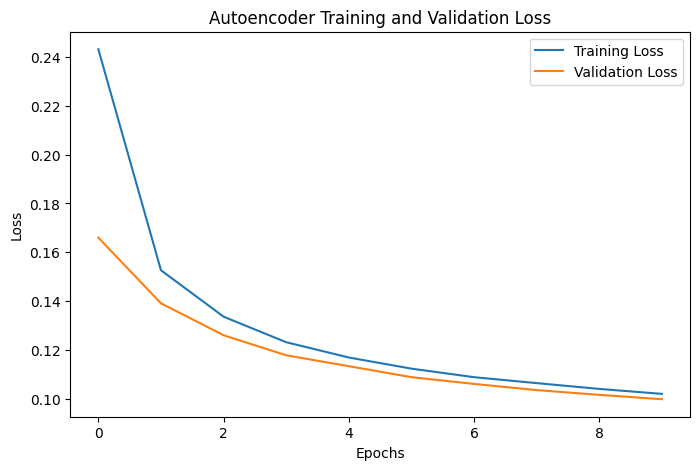

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0998
Test Reconstruction Loss: 0.09983158111572266


In [3]:
print("Name: Piriyadharshini N\nRoll no.: 24BAD086\nExperiment: 8\n")

# Compile the autoencoder
autoencoder.compile(
    optimizer='adam',
    loss='binary_crossentropy'
)

# Train the autoencoder
history = autoencoder.fit(
    x_train,
    x_train,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)

# Plot training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Autoencoder Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Evaluate model
test_loss = autoencoder.evaluate(x_test, x_test)

print("Test Reconstruction Loss:", test_loss)

Name: Piriyadharshini N
Roll no.: 24BAD086
Experiment: 8

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Original Input Dimension: 784
Latent Dimension: 32
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


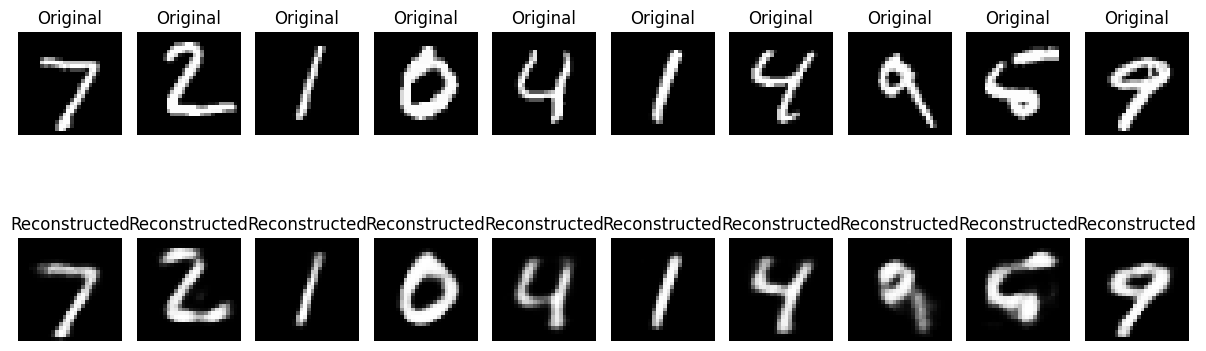

Autoencoder model saved successfully!


In [4]:
print("Name: Piriyadharshini N\nRoll no.: 24BAD086\nExperiment: 8\n")

# Extract latent features
latent_features = encoder.predict(x_test)

# Display dimensions
print("Original Input Dimension:", x_test.shape[1])
print("Latent Dimension:", latent_features.shape[1])

# Reconstruct images using decoder
reconstructed = decoder.predict(latent_features)

# Display original and reconstructed images
plt.figure(figsize=(12, 5))

for i in range(10):

    # Original images
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    # Reconstructed images
    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed[i].reshape(28, 28), cmap='gray')
    plt.title("Reconstructed")
    plt.axis('off')

plt.tight_layout()
plt.show()

# Save the trained model
autoencoder.save("autoencoder_model.keras")

print("Autoencoder model saved successfully!")